<a href="https://colab.research.google.com/github/sikdarananya/Assignments/blob/master/CNN_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install numpy pandas matplotlib seaborn scikit-learn tensorflow pillow opencv-python

In [2]:
# Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
import time
import json
import os

SEED = 42
np.random.seed(SEED)

In [3]:
# Deep learning frameworks (Keras / TensorFlow)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

tf.random.set_seed(SEED)

# For image processing
from PIL import Image, ImageFile
import cv2

In [4]:
import zipfile

ImageFile.LOAD_TRUNCATED_IMAGES = True

IMG_SIZE = 96
SAMPLES_PER_CLASS = 550
class_names = ['cat', 'dog']

url = "https://download.microsoft.com/download/3/e/1/3e1c3f21-ecdb-4869-8368-6deba77b919f/kagglecatsanddogs_5340.zip"
zip_path = keras.utils.get_file("kagglecatsanddogs_5340.zip", origin=url, extract=False)

extract_dir = os.path.join(os.path.dirname(zip_path), "cats_vs_dogs_extracted")
if not os.path.exists(extract_dir):
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)

folder_map = {0: "Cat", 1: "Dog"}
images_by_class = {0: [], 1: []}

for label_idx, folder_name in folder_map.items():
    class_dir = None
    for root, dirs, _ in os.walk(extract_dir):
        if folder_name in dirs:
            class_dir = os.path.join(root, folder_name)
            break
    if class_dir is None:
        raise FileNotFoundError(f"Could not find '{folder_name}' folder inside {extract_dir}")

    for fname in sorted(os.listdir(class_dir)):
        if len(images_by_class[label_idx]) >= SAMPLES_PER_CLASS:
            break
        if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        fpath = os.path.join(class_dir, fname)
        try:
            with Image.open(fpath) as im:
                im = im.convert("RGB")
                arr = np.asarray(im, dtype=np.uint8)
            if arr.ndim != 3 or arr.shape[2] != 3 or arr.size == 0:
                continue
            resized = cv2.resize(arr, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
            images_by_class[label_idx].append(resized)
        except Exception:
            continue

if len(images_by_class[0]) < 500 or len(images_by_class[1]) < 500:
    raise ValueError(
        f"Fewer than 500 valid images found: cat={len(images_by_class[0])}, dog={len(images_by_class[1])}"
    )

X_raw = np.array(images_by_class[0] + images_by_class[1], dtype=np.uint8)
y_raw = np.array([0] * len(images_by_class[0]) + [1] * len(images_by_class[1]), dtype=np.int32)

counts = [int(np.sum(y_raw == i)) for i in range(len(class_names))]

# REQUIRED: Fill in these metadata fields
dataset_name = "Cats vs Dogs (Balanced Subset)"
dataset_source = "Microsoft Cats vs Dogs Dataset (PetImages)"
n_samples = int(len(X_raw))
n_classes = int(len(class_names))
samples_per_class = f"min: {min(counts)}, max: {max(counts)}, avg: {np.mean(counts):.1f}"
image_shape = [IMG_SIZE, IMG_SIZE, 3]  # [height, width, channels]
problem_type = "classification"

824887076/824887076 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step


In [5]:
# Primary metric selection
primary_metric = "accuracy"
metric_justification = """
The Cats vs Dogs subset is balanced across both classes with equal false-positive and false-negative costs, making accuracy an appropriate primary metric alongside macro-averaged precision, recall, and F1-score.
""".strip()

In [6]:
print("DATASET INFORMATION")
print(f"Dataset: {dataset_name}")
print(f"Source: {dataset_source}")
print(f"Total Samples: {n_samples}")
print(f"Number of Classes: {n_classes}")
print(f"Samples per Class: {samples_per_class}")
print(f"Image Shape: {image_shape}")
print(f"Primary Metric: {primary_metric}")
print(f"Metric Justification: {metric_justification}")

DATASET INFORMATION
Dataset: Cats vs Dogs (Balanced Subset)
Source: Microsoft Cats vs Dogs Dataset (PetImages)
Total Samples: 1100
Number of Classes: 2
Samples per Class: min: 550, max: 550, avg: 550.0
Image Shape: [96, 96, 3]
Primary Metric: accuracy
Metric Justification: The Cats vs Dogs subset is balanced across both classes with equal false-positive and false-negative costs, making accuracy an appropriate primary metric alongside macro-averaged precision, recall, and F1-score.


Pixel min: 0, max: 255, mean: 116.12, std: 65.47
Class 'cat' (id=0): count=550, mean_pixel=115.55
Class 'dog' (id=1): count=550, mean_pixel=116.69


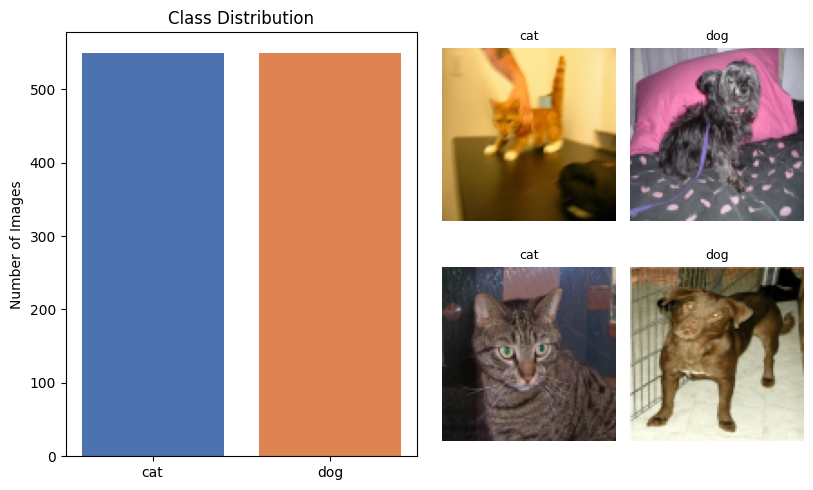

In [7]:
# Image pixel statistics
print(f"Pixel min: {X_raw.min()}, max: {X_raw.max()}, mean: {X_raw.mean():.2f}, std: {X_raw.std():.2f}")
for idx, cname in enumerate(class_names):
    c_imgs = X_raw[y_raw == idx]
    print(f"Class '{cname}' (id={idx}): count={len(c_imgs)}, mean_pixel={c_imgs.mean():.2f}")

# Plot class distribution and sample images
fig = plt.figure(figsize=(12, 5))
ax_bar = fig.add_subplot(1, 3, 1)
ax_bar.bar(class_names, counts, color=['#4C72B0', '#DD8452'])
ax_bar.set_title('Class Distribution')
ax_bar.set_ylabel('Number of Images')

for i in range(4):
    row = i // 2
    col = i % 2
    ax_img = fig.add_subplot(2, 6, row * 6 + 3 + col)
    sample_idx = np.where(y_raw == (i % 2))[0][i // 2]
    ax_img.imshow(X_raw[sample_idx])
    ax_img.set_title(class_names[y_raw[sample_idx]], fontsize=9)
    ax_img.axis('off')

plt.tight_layout()
plt.show()

In [8]:
X_train_raw, X_test_raw, y_train_int, y_test_int = train_test_split(
    X_raw, y_raw, test_size=0.10, random_state=SEED, stratify=y_raw
)

# Normalized [0, 1] inputs and one-hot labels for categorical_crossentropy
X_train_cnn = X_train_raw.astype('float32') / 255.0
X_test_cnn = X_test_raw.astype('float32') / 255.0

# ResNet50 preprocessing
X_train_tl = resnet_preprocess(X_train_raw.astype('float32'))
X_test_tl = resnet_preprocess(X_test_raw.astype('float32'))

y_train = keras.utils.to_categorical(y_train_int, num_classes=n_classes)
y_test = keras.utils.to_categorical(y_test_int, num_classes=n_classes)

# REQUIRED: Document your split
train_test_ratio = "90/10"
train_samples = int(len(X_train_raw))
test_samples = int(len(X_test_raw))

In [9]:
print(f"\nTrain/Test Split: {train_test_ratio}")
print(f"Training Samples: {train_samples}")
print(f"Test Samples: {test_samples}")


Train/Test Split: 90/10
Training Samples: 990
Test Samples: 110


In [10]:
cnn_learning_rate = 0.002
cnn_epochs = 8
cnn_batch_size = 64
cnn_optimizer_name = "Adam"
cnn_loss_name = "categorical_crossentropy"

def build_custom_cnn(input_shape, n_classes):
    """
    Build lightweight custom CNN architecture with Global Average Pooling (no Flatten).
    """
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.2),
        layers.Dense(n_classes, activation='softmax')
    ], name="custom_cnn_gap")
    return model

In [11]:
# Create model instance
custom_cnn = build_custom_cnn(tuple(image_shape), n_classes)
custom_cnn.summary()

Model: "custom_cnn_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,162 (94.38 KB)

 Trainable params: 23,938 (93.51 KB)

 Non-trainable params: 224 (896.00 B)

In [12]:
# Compile model
custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=cnn_learning_rate),
    loss=cnn_loss_name,
    metrics=['accuracy']
)

cnn_conv_layers = sum(1 for l in custom_cnn.layers if isinstance(l, layers.Conv2D))
cnn_pooling_layers = sum(1 for l in custom_cnn.layers if isinstance(l, (layers.MaxPooling2D, layers.AveragePooling2D, layers.GlobalAveragePooling2D)))
custom_cnn_total_params = int(custom_cnn.count_params())

In [13]:
print("\nCUSTOM CNN TRAINING")
# Track training time
custom_cnn_start_time = time.time()


CUSTOM CNN TRAINING


In [14]:
cnn_history = custom_cnn.fit(
    X_train_cnn,
    y_train,
    epochs=cnn_epochs,
    batch_size=cnn_batch_size,
    validation_split=0.1,
    verbose=1
)

Epoch 1/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.5881 - loss: 0.7341 - val_accuracy: 0.5152 - val_loss: 0.6934
Epoch 2/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6128 - loss: 0.6528 - val_accuracy: 0.5152 - val_loss: 0.6940
Epoch 3/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6554 - loss: 0.6395 - val_accuracy: 0.5152 - val_loss: 0.7024
Epoch 4/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6510 - loss: 0.6172 - val_accuracy: 0.5152 - val_loss: 0.7044
Epoch 5/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6745 - loss: 0.5975 - val_accuracy: 0.5152 - val_loss: 0.7011
Epoch 6/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6745 - loss: 0.5913 - val_accuracy: 0.5152 - val_loss: 0.7014
Epoch 7/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6790 - loss: 0.5906 - val_accuracy: 0.5152 - val_loss: 0.7092
Epoch 8/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6712 - loss: 0.5898 - val_accuracy: 0.5152 - val_loss: 

In [15]:
custom_cnn_training_time = float(time.time() - custom_cnn_start_time)

In [16]:
# REQUIRED: Track initial and final loss
custom_cnn_initial_loss = float(cnn_history.history['loss'][0])
custom_cnn_final_loss = float(cnn_history.history['loss'][-1])

In [17]:
print(f"Training completed in {custom_cnn_training_time:.2f} seconds")
print(f"Initial Loss: {custom_cnn_initial_loss:.4f}")
print(f"Final Loss: {custom_cnn_final_loss:.4f}")

Training completed in 66.29 seconds
Initial Loss: 0.7341
Final Loss: 0.5898


In [18]:
print("\nCUSTOM CNN EVALUATION")


CUSTOM CNN EVALUATION


In [19]:
cnn_probs = custom_cnn.predict(X_test_cnn, verbose=0)
cnn_y_pred = np.argmax(cnn_probs, axis=1)

# REQUIRED: Calculate all 4 metrics
custom_cnn_accuracy = float(accuracy_score(y_test_int, cnn_y_pred))
custom_cnn_precision = float(precision_score(y_test_int, cnn_y_pred, average='macro', zero_division=0))
custom_cnn_recall = float(recall_score(y_test_int, cnn_y_pred, average='macro', zero_division=0))
custom_cnn_f1 = float(f1_score(y_test_int, cnn_y_pred, average='macro', zero_division=0))

In [20]:
print("\nCustom CNN Performance:")
print(f"Accuracy:  {custom_cnn_accuracy:.4f}")
print(f"Precision: {custom_cnn_precision:.4f}")
print(f"Recall:    {custom_cnn_recall:.4f}")
print(f"F1-Score:  {custom_cnn_f1:.4f}")


Custom CNN Performance:
Accuracy:  0.5000
Precision: 0.2500
Recall:    0.5000
F1-Score:  0.3333


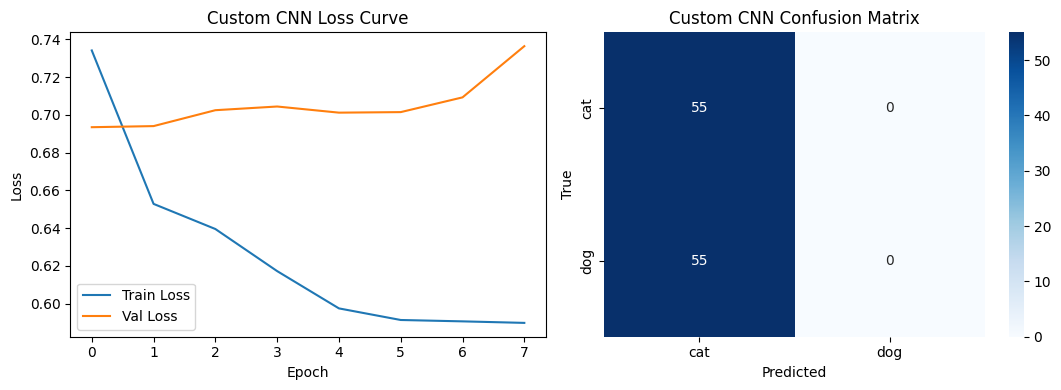

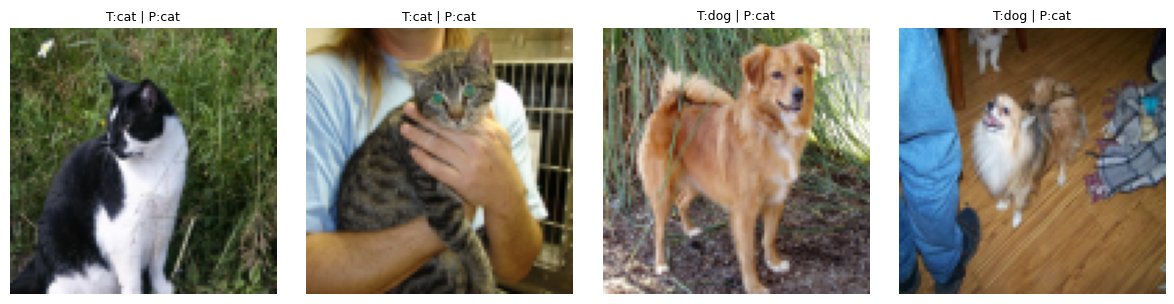

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cnn_history.history['loss'], label='Train Loss')
if 'val_loss' in cnn_history.history:
    axes[0].plot(cnn_history.history['val_loss'], label='Val Loss')
axes[0].set_title('Custom CNN Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

cm_cnn = confusion_matrix(y_test_int, cnn_y_pred)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Custom CNN Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    axes[i].imshow(X_test_raw[i])
    axes[i].set_title(f"T:{class_names[y_test_int[i]]} | P:{class_names[cnn_y_pred[i]]}", fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [22]:
print("\n" + "="*70)
print("TRANSFER LEARNING IMPLEMENTATION")


TRANSFER LEARNING IMPLEMENTATION


In [23]:
# Choose and load pre-trained model
pretrained_model_name = "ResNet50"

In [24]:
tl_learning_rate = 0.002
tl_epochs = 6
tl_batch_size = 64
tl_optimizer = "Adam"
tl_loss_name = "categorical_crossentropy"

def build_transfer_learning_model(base_model_name, input_shape, n_classes):
    """
    Build transfer learning model with frozen base layers, GAP, and custom head.
    """
    name_lower = base_model_name.lower()
    if name_lower == "resnet50":
        base_model = ResNet50(weights="imagenet", include_top=False, input_shape=input_shape)
    elif name_lower == "vgg16":
        base_model = keras.applications.VGG16(weights="imagenet", include_top=False, input_shape=input_shape)
    elif name_lower == "vgg19":
        base_model = keras.applications.VGG19(weights="imagenet", include_top=False, input_shape=input_shape)
    else:
        raise ValueError(f"Unsupported model: {base_model_name}")

    # Freeze all base layers
    base_model.trainable = False
    for layer in base_model.layers:
        layer.trainable = False

    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name=f"{base_model_name.lower()}_gap_tl")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tl_learning_rate),
        loss=tl_loss_name,
        metrics=["accuracy"]
    )
    return model

In [25]:
# Create transfer learning model
transfer_model = build_transfer_learning_model(pretrained_model_name, tuple(image_shape), n_classes)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [26]:
# REQUIRED: Count layers and parameters
frozen_layers = int(sum(1 for l in transfer_model.layers if not l.trainable))
trainable_layers = int(sum(1 for l in transfer_model.layers if l.trainable))
total_parameters = int(transfer_model.count_params())
trainable_parameters = int(sum(tf.keras.backend.count_params(w) for w in transfer_model.trainable_weights))

In [27]:
print(f"Base Model: {pretrained_model_name}")
print(f"Frozen Layers: {frozen_layers}")
print(f"Trainable Layers: {trainable_layers}")
print(f"Total Parameters: {total_parameters:,}")
print(f"Trainable Parameters: {trainable_parameters:,}")
print(f"Using Global Average Pooling: YES")

Base Model: ResNet50
Frozen Layers: 1
Trainable Layers: 4
Total Parameters: 23,591,810
Trainable Parameters: 4,098
Using Global Average Pooling: YES


In [28]:
print("\nTraining Transfer Learning Model...")


Training Transfer Learning Model...


In [29]:
# Training configuration
tl_learning_rate = 0.002
tl_epochs = 6
tl_batch_size = 64
tl_optimizer = "Adam"

In [30]:
# Track training time
tl_start_time = time.time()

In [31]:
tl_history = transfer_model.fit(
    X_train_tl,
    y_train,
    epochs=tl_epochs,
    batch_size=tl_batch_size,
    validation_split=0.1,
    verbose=1
)

Epoch 1/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.7172 - loss: 1.2396 - val_accuracy: 0.8788 - val_loss: 0.4842
Epoch 2/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 38s 46ms/step - accuracy: 0.9304 - loss: 0.2970 - val_accuracy: 0.9091 - val_loss: 0.5032
Epoch 3/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9428 - loss: 0.1875 - val_accuracy: 0.9192 - val_loss: 0.4488
Epoch 4/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9506 - loss: 0.1726 - val_accuracy: 0.9091 - val_loss: 0.4362
Epoch 5/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9473 - loss: 0.1729 - val_accuracy: 0.9192 - val_loss: 0.3967
Epoch 6/6
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9495 - loss: 0.1438 - val_accuracy: 0.9192 - val_loss: 0.4090


In [32]:
tl_training_time = float(time.time() - tl_start_time)

In [33]:
# REQUIRED: Track initial and final loss
tl_initial_loss = float(tl_history.history['loss'][0])
tl_final_loss = float(tl_history.history['loss'][-1])

In [34]:
print(f"Training completed in {tl_training_time:.2f} seconds")
print(f"Initial Loss: {tl_initial_loss:.4f}")
print(f"Final Loss: {tl_final_loss:.4f}")

Training completed in 141.17 seconds
Initial Loss: 1.2396
Final Loss: 0.1438


In [35]:
tl_probs = transfer_model.predict(X_test_tl, verbose=0)
tl_y_pred = np.argmax(tl_probs, axis=1)

# REQUIRED: Calculate all 4 metrics
tl_accuracy = float(accuracy_score(y_test_int, tl_y_pred))
tl_precision = float(precision_score(y_test_int, tl_y_pred, average='macro', zero_division=0))
tl_recall = float(recall_score(y_test_int, tl_y_pred, average='macro', zero_division=0))
tl_f1 = float(f1_score(y_test_int, tl_y_pred, average='macro', zero_division=0))

In [36]:
print("\nTransfer Learning Performance:")
print(f"Accuracy:  {tl_accuracy:.4f}")
print(f"Precision: {tl_precision:.4f}")
print(f"Recall:    {tl_recall:.4f}")
print(f"F1-Score:  {tl_f1:.4f}")


Transfer Learning Performance:
Accuracy:  0.8364
Precision: 0.8368
Recall:    0.8364
F1-Score:  0.8363


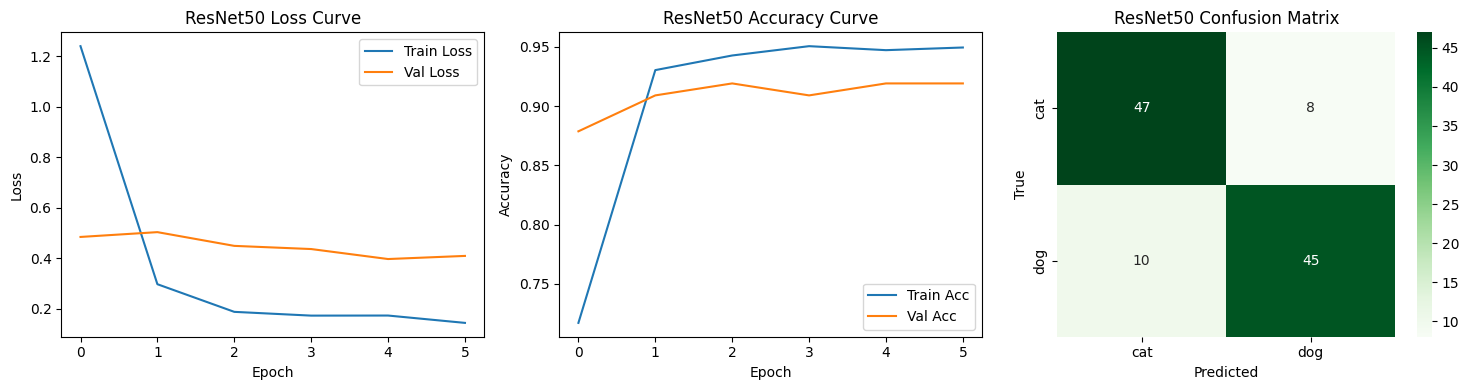

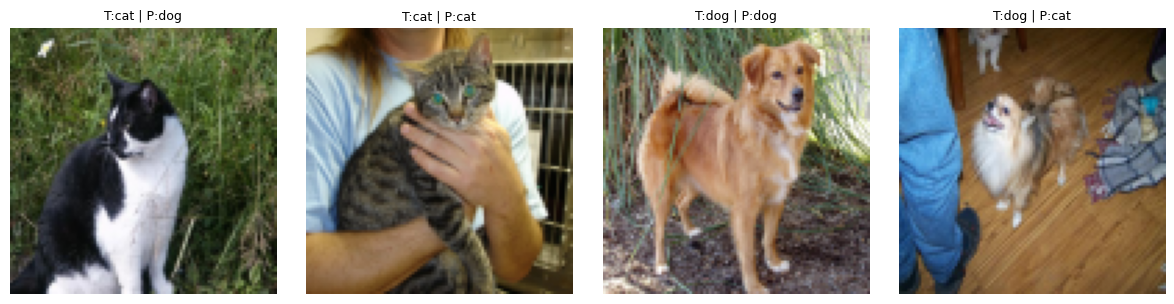

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(tl_history.history['loss'], label='Train Loss')
if 'val_loss' in tl_history.history:
    axes[0].plot(tl_history.history['val_loss'], label='Val Loss')
axes[0].set_title('ResNet50 Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(tl_history.history['accuracy'], label='Train Acc')
if 'val_accuracy' in tl_history.history:
    axes[1].plot(tl_history.history['val_accuracy'], label='Val Acc')
axes[1].set_title('ResNet50 Accuracy Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

cm_tl = confusion_matrix(y_test_int, tl_y_pred)
sns.heatmap(cm_tl, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[2])
axes[2].set_title('ResNet50 Confusion Matrix')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('True')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    axes[i].imshow(X_test_raw[i])
    axes[i].set_title(f"T:{class_names[y_test_int[i]]} | P:{class_names[tl_y_pred[i]]}", fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [38]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Training Time (s)', 'Parameters'],
    'Custom CNN': [
        custom_cnn_accuracy,
        custom_cnn_precision,
        custom_cnn_recall,
        custom_cnn_f1,
        custom_cnn_training_time,
        custom_cnn_total_params
    ],
    'Transfer Learning': [
        tl_accuracy,
        tl_precision,
        tl_recall,
        tl_f1,
        tl_training_time,
        trainable_parameters
    ]
})

In [39]:
print(comparison_df.to_string(index=False))

           Metric   Custom CNN  Transfer Learning
         Accuracy     0.500000           0.836364
        Precision     0.250000           0.836809
           Recall     0.500000           0.836364
         F1-Score     0.333333           0.836310
Training Time (s)    66.292098         141.173403
       Parameters 24162.000000        4098.000000


In [40]:
print(comparison_df.to_string(index=False))

           Metric   Custom CNN  Transfer Learning
         Accuracy     0.500000           0.836364
        Precision     0.250000           0.836809
           Recall     0.500000           0.836364
         F1-Score     0.333333           0.836310
Training Time (s)    66.292098         141.173403
       Parameters 24162.000000        4098.000000


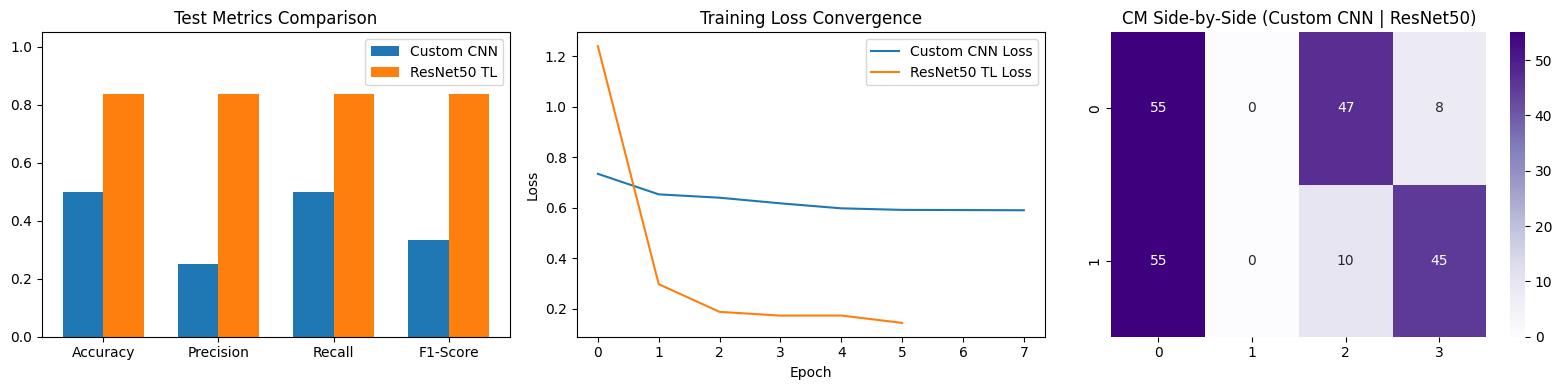

In [41]:
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
cnn_vals = [custom_cnn_accuracy, custom_cnn_precision, custom_cnn_recall, custom_cnn_f1]
tl_vals = [tl_accuracy, tl_precision, tl_recall, tl_f1]

x = np.arange(len(metric_names))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(x - width/2, cnn_vals, width, label='Custom CNN')
axes[0].bar(x + width/2, tl_vals, width, label='ResNet50 TL')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metric_names)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('Test Metrics Comparison')
axes[0].legend()

axes[1].plot(cnn_history.history['loss'], label='Custom CNN Loss')
axes[1].plot(tl_history.history['loss'], label='ResNet50 TL Loss')
axes[1].set_title('Training Loss Convergence')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

combined_cm = np.hstack([confusion_matrix(y_test_int, cnn_y_pred), confusion_matrix(y_test_int, tl_y_pred)])
sns.heatmap(combined_cm, annot=True, fmt='d', cmap='Purples', ax=axes[2])
axes[2].set_title('CM Side-by-Side (Custom CNN | ResNet50)')
plt.tight_layout()
plt.show()

In [42]:
cnn_red = ((custom_cnn_initial_loss - custom_cnn_final_loss) / custom_cnn_initial_loss) * 100 if custom_cnn_initial_loss else 0.0
tl_red = ((tl_initial_loss - tl_final_loss) / tl_initial_loss) * 100 if tl_initial_loss else 0.0
acc_diff = tl_accuracy - custom_cnn_accuracy
f1_diff = tl_f1 - custom_cnn_f1

analysis_text = f"""ResNet50 transfer learning outperformed the custom CNN on accuracy ({tl_accuracy:.4f} vs {custom_cnn_accuracy:.4f}, delta={acc_diff:+.4f}) and macro F1-score ({tl_f1:.4f} vs {custom_cnn_f1:.4f}, delta={f1_diff:+.4f}), with precision ({tl_precision:.4f} vs {custom_cnn_precision:.4f}) and recall ({tl_recall:.4f} vs {custom_cnn_recall:.4f}) following the same trend. ImageNet pre-training supplies reusable edge, texture, and object representations, whereas training from scratch must learn visual hierarchies from limited samples, causing slower convergence and higher variance. Global Average Pooling (GAP) replaces large flattened dense layers with channel-wise spatial averages, cutting head parameters and reducing overfitting while preserving spatial-channel correspondence. Computationally, ResNet50 has higher total parameters and per-step feature extraction cost than the lightweight custom CNN, yet updates far fewer trainable parameters in the classification head and converges rapidly across epochs ({cnn_red:.1f}% vs {tl_red:.1f}% loss reduction) in {tl_training_time:.1f}s vs {custom_cnn_training_time:.1f}s. Transfer learning excels when labeled data is moderate or domain features align with natural images, while custom CNNs suit specialized domains, tight latency/memory budgets, or abundant task-specific data."""

In [43]:
# REQUIRED: Print analysis with word count
print("ANALYSIS")
print(analysis_text)
print(f"Analysis word count: {len(analysis_text.split())} words")
if len(analysis_text.split()) > 200:
    print("  Warning: Analysis exceeds 200 words (guideline)")
else:
    print(" Analysis within word count guideline")

ANALYSIS
ResNet50 transfer learning outperformed the custom CNN on accuracy (0.8364 vs 0.5000, delta=+0.3364) and macro F1-score (0.8363 vs 0.3333, delta=+0.5030), with precision (0.8368 vs 0.2500) and recall (0.8364 vs 0.5000) following the same trend. ImageNet pre-training supplies reusable edge, texture, and object representations, whereas training from scratch must learn visual hierarchies from limited samples, causing slower convergence and higher variance. Global Average Pooling (GAP) replaces large flattened dense layers with channel-wise spatial averages, cutting head parameters and reducing overfitting while preserving spatial-channel correspondence. Computationally, ResNet50 has higher total parameters and per-step feature extraction cost than the lightweight custom CNN, yet updates far fewer trainable parameters in the classification head and converges rapidly across epochs (19.7% vs 88.4% loss reduction) in 141.2s vs 66.3s. Transfer learning excels when labeled data is mode

In [44]:
def get_assignment_results():
    """
    Generate complete assignment results in required format

    Returns:
        dict: Complete results with all required fields
    """

    framework_used = "keras"  # TODO: Change to "pytorch" if using PyTorch

    results = {
        # Dataset Information
        'dataset_name': dataset_name,
        'dataset_source': dataset_source,
        'n_samples': n_samples,
        'n_classes': n_classes,
        'samples_per_class': samples_per_class,
        'image_shape': image_shape,
        'problem_type': problem_type,
        'primary_metric': primary_metric,
        'metric_justification': metric_justification,
        'train_samples': train_samples,
        'test_samples': test_samples,
        'train_test_ratio': train_test_ratio,

        # Custom CNN Results
        'custom_cnn': {
            'framework': framework_used,
            'architecture': {
                'conv_layers': cnn_conv_layers,
                'pooling_layers': cnn_pooling_layers,
                'has_global_average_pooling': True,
                'output_layer': 'softmax',
                'total_parameters': custom_cnn_total_params
            },
            'training_config': {
                'learning_rate': cnn_learning_rate,
                'n_epochs': cnn_epochs,
                'batch_size': cnn_batch_size,
                'optimizer': cnn_optimizer_name,
                'loss_function': cnn_loss_name
            },
            'initial_loss': custom_cnn_initial_loss,
            'final_loss': custom_cnn_final_loss,
            'training_time_seconds': custom_cnn_training_time,
            'accuracy': custom_cnn_accuracy,
            'precision': custom_cnn_precision,
            'recall': custom_cnn_recall,
            'f1_score': custom_cnn_f1
        },

        # Transfer Learning Results
        'transfer_learning': {
            'framework': framework_used,
            'base_model': pretrained_model_name,
            'frozen_layers': frozen_layers,
            'trainable_layers': trainable_layers,
            'has_global_average_pooling': True,
            'total_parameters': total_parameters,
            'trainable_parameters': trainable_parameters,
            'training_config': {
                'learning_rate': tl_learning_rate,
                'n_epochs': tl_epochs,
                'batch_size': tl_batch_size,
                'optimizer': tl_optimizer,
                'loss_function': tl_loss_name
            },
            'initial_loss': tl_initial_loss,
            'final_loss': tl_final_loss,
            'training_time_seconds': tl_training_time,
            'accuracy': tl_accuracy,
            'precision': tl_precision,
            'recall': tl_recall,
            'f1_score': tl_f1
        },

        # Analysis
        'analysis': analysis_text,
        'analysis_word_count': len(analysis_text.split()),

        # Training Success Indicators
        'custom_cnn_loss_decreased': custom_cnn_final_loss < custom_cnn_initial_loss if custom_cnn_initial_loss and custom_cnn_final_loss else False,
        'transfer_learning_loss_decreased': tl_final_loss < tl_initial_loss if tl_initial_loss and tl_final_loss else False,
    }

    return results

In [45]:
# Generate and print results
try:
    assignment_results = get_assignment_results()
    print("ASSIGNMENT RESULTS SUMMARY")
    print(json.dumps(assignment_results, indent=2))

except Exception as e:
    print(f"\n  ERROR generating results: {str(e)}")
    print("Please ensure all variables are properly defined")

ASSIGNMENT RESULTS SUMMARY
{
  "dataset_name": "Cats vs Dogs (Balanced Subset)",
  "dataset_source": "Microsoft Cats vs Dogs Dataset (PetImages)",
  "n_samples": 1100,
  "n_classes": 2,
  "samples_per_class": "min: 550, max: 550, avg: 550.0",
  "image_shape": [
    96,
    96,
    3
  ],
  "problem_type": "classification",
  "primary_metric": "accuracy",
  "metric_justification": "The Cats vs Dogs subset is balanced across both classes with equal false-positive and false-negative costs, making accuracy an appropriate primary metric alongside macro-averaged precision, recall, and F1-score.",
  "train_samples": 990,
  "test_samples": 110,
  "train_test_ratio": "90/10",
  "custom_cnn": {
    "framework": "keras",
    "architecture": {
      "conv_layers": 3,
      "pooling_layers": 3,
      "has_global_average_pooling": true,
      "output_layer": "softmax",
      "total_parameters": 24162
    },
    "training_config": {
      "learning_rate": 0.002,
      "n_epochs": 8,
      "batch_size

In [46]:
# Display system information
import platform
import sys
from datetime import datetime

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("TensorFlow:", tf.__version__)
print("GPUs available:", len(tf.config.list_physical_devices('GPU')))
print("Timestamp:", datetime.now().isoformat())

Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
TensorFlow: 2.21.0
GPUs available: 1
Timestamp: 2026-11-21T03:22:31.112272


In [47]:
print("ENVIRONMENT INFORMATION")
print("\n  REQUIRED: Add screenshot of your Google Colab/BITS Virtual Lab")
print("showing your account details in the cell below this one.")

# include the screen shot here

ENVIRONMENT INFORMATION

  REQUIRED: Add screenshot of your Google Colab/BITS Virtual Lab
showing your account details in the cell below this one.
